# Временные диаграммы персистентности — отчёт Результата 2

**Задача 2 первого этапа.** Подпакет `tdadyn.zigzag`: зигзаг-персистентность на динамических
графах и локализация топологических событий во времени.

Это продолжение отчёта по Задаче 5 (`notebooks/report.ipynb`). Там построены наборы данных,
у которых **правильный ответ известен заранее**; здесь по ним проверяется алгоритм. Читатель
предполагается знакомым с первым отчётом: числа Бетти, персистентные гомологии и устройство
семейства 2 ниже не пересказываются.

---

## 0. Что требовалось сделать и что получилось

Критерий из заявки: **корректное обнаружение заранее известных событий** — рождения, слияния,
исчезновения циклов — на синтетических графах с контролируемой динамикой; метрики recall и
precision событий и ошибка локализации во времени.

Коротко, что вышло:

| | |
|---|---|
| На двух наборах семейства 2 | recall и precision по **1.0**, ошибка локализации 0 |
| Барштрих-код посчитан **дважды независимо** | оракул и Dionysus совпали на 3192 барах, 0 расхождений |
| На нулевой модели | ложное срабатывание на **98.3%** снимков — измерено, а не заявлено |
| Под шумом | recall падает медленно, precision обваливается до **0.17%** |

И — что не менее важно — отчёт называет, **чего эти метрики не проверяют**. Раздел 8.

Дальше по порядку: что такое топологическое событие (1), почему обычная персистентность здесь
не работает (2), как устроен зигзаг (3–4), как ответ получен двумя способами (5–6), как
барштрих-код превращается в события (7–8), и что происходит, когда истины нет или она
зашумлена (9–11).

### Откуда берутся числа

Ни одно число ниже не вычисляется в этом ноутбуке. Все они прочитаны из артефакта, который
производит одна команда:

```bash
make results          # python -m tdadyn.results --config config.yaml --results
```

Артефакт лежит в `data/synthetic/results/zigzag_events.json` и хранится в git — он не данные,
а **запись замера**: наборы регенерируемы из конфига и seed, а утверждение «отчёт написан
против вот этих чисел» — нет. Пересборка даёт тот же `content_sha256`; меняется только
отметка времени.

Наборы данных ноутбук загружает только для иллюстраций: нарисованный снимок графа отчётной
величиной не является.

> HTML-версия подгружает MathJax с CDN — формулы без сети покажутся исходным текстом. Числа,
> таблицы и рисунки от сети не зависят.

In [1]:
import json, pathlib
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})
PALETTE = plt.get_cmap("tab10")

ROOT = pathlib.Path("..") / "data" / "synthetic"
ART = json.loads((ROOT / "results" / "zigzag_events.json").read_text(encoding="utf-8"))
CLEAN = {e["dataset_id"].split("_N")[0]: e for e in ART["datasets"] if e["kind"] == "clean"}
NOISY = [e for e in ART["datasets"] if e["kind"] == "noisy"]

def label(position):
    """Позиция на I -> индекс, каким его пишут документы: 12 или 11½.

    Форматирование, а не вычисление: чётная позиция есть снимок, нечётная — объединение
    за ним, и это правило записано в самом артефакте (раздел 3).
    """
    return f"{position // 2}" if position % 2 == 0 else f"{position // 2}½"

print(f"артефакт версии {ART['format_version']}, собран {ART['generated_at']}")
print(f"пакет {ART['package_version']}, sha256 {ART['content_sha256'][:16]}...")
print(f"наборов {len(ART['datasets'])}: {len(CLEAN)} чистых, {len(NOISY)} зашумлённых")

артефакт версии 1, собран 2026-08-23T08:53:36Z
пакет 0.1.0, sha256 6be89481b849170e...
наборов 18: 2 чистых, 16 зашумлённых


---

## 1. Топологическое событие: что именно надо найти

Динамический граф — это последовательность снимков $G_0, \dots, G_{T-1}$ на одном и том же
множестве вершин. Между соседними снимками рёбра появляются и исчезают, и вместе с ними
появляются и исчезают **топологические признаки**: компоненты связности ($H_0$) и независимые
циклы ($H_1$).

Событие — это момент, когда признак рождается или умирает. На языке гомологий операций ровно
две, `birth` и `death`: слияния и разделения классов в барштрих-коде не существует, и
интуитивное «цикл разделился надвое» на этом языке означает **рождение** нового класса.

Основной набор — `cycle_lifecycle` на 24 вершинах и 60 снимках. Его сценарий выбран так,
чтобы каждое событие было следствием одного понятного изменения графа.

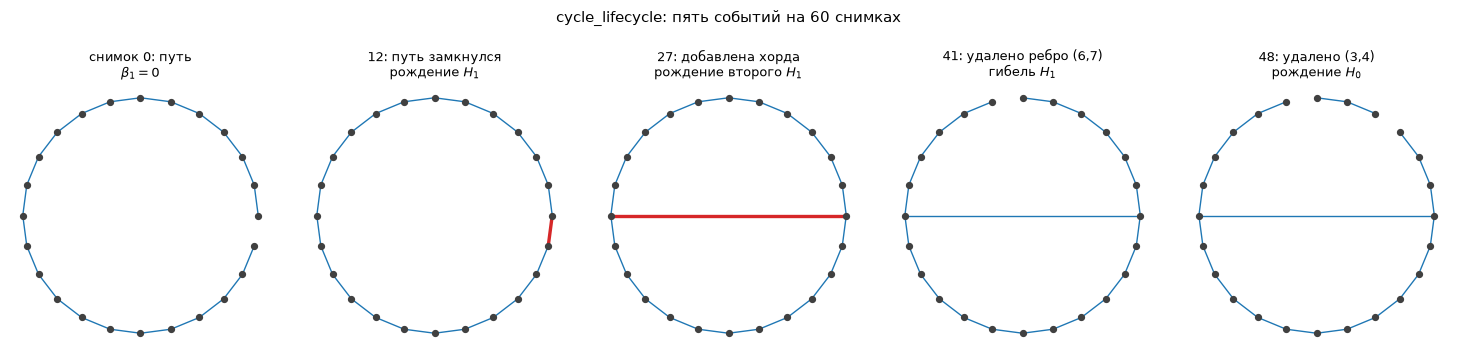

In [2]:
from tdadyn.core import adjacency_from_snapshot, load_dataset

LIFECYCLE = load_dataset(next((ROOT / "dynamic_graph").glob("cycle_lifecycle_*")))
LOOP = load_dataset(next((ROOT / "dynamic_graph").glob("geometric_loop_*")))

def graph_at(dataset, snapshot):
    truth = dataset.ground_truth
    return adjacency_from_snapshot(dataset.snapshots[snapshot],
                                   edge_rule=truth.edge_rule,
                                   edge_threshold=truth.edge_threshold)

def draw_graph(ax, adjacency, title, highlight=(), n=None):
    n = n or adjacency.shape[0]
    angle = np.arange(n) * 2 * np.pi / n
    xy = np.c_[np.cos(angle), np.sin(angle)]
    for i, j in zip(*np.triu_indices(n, 1)):
        if adjacency[i, j]:
            colour = "tab:red" if (i, j) in highlight else "tab:blue"
            width = 2.2 if (i, j) in highlight else 0.9
            ax.plot(*xy[[i, j]].T, color=colour, lw=width, zorder=2)
    ax.scatter(*xy.T, s=14, color="0.25", zorder=3)
    ax.set_title(title, fontsize=8.5)
    ax.set_aspect("equal"); ax.axis("off")

STAGES = [(0, "снимок 0: путь\n$\\beta_1 = 0$", ()),
          (12, "12: путь замкнулся\nрождение $H_1$", ((0, 23),)),
          (27, "27: добавлена хорда\nрождение второго $H_1$", ((0, 12),)),
          (41, "41: удалено ребро (6,7)\nгибель $H_1$", ()),
          (48, "48: удалено (3,4)\nрождение $H_0$", ())]

fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.0))
for ax, (snap, title, hi) in zip(axes, STAGES):
    draw_graph(ax, graph_at(LIFECYCLE, snap), title, highlight=hi)
fig.suptitle("cycle_lifecycle: пять событий на 60 снимках", y=1.06, fontsize=10)
plt.tight_layout(); plt.show()

Красным выделены рёбра, добавление которых порождает событие. Обратите внимание на снимок
27: хорда $(0,12)$ делит 24-цикл на два цикла длины 13, и на языке графов это «разделение», а
на языке гомологий — **рождение** нового класса.

Истина этого набора — не наблюдение, а конструкция: список событий записан планировщиком до
всякого счёта, а кривая Бетти посчитана независимой эталонной реализацией по **записанным на
диск** снимкам. Два источника сверяются между собой тестом Задачи 5.

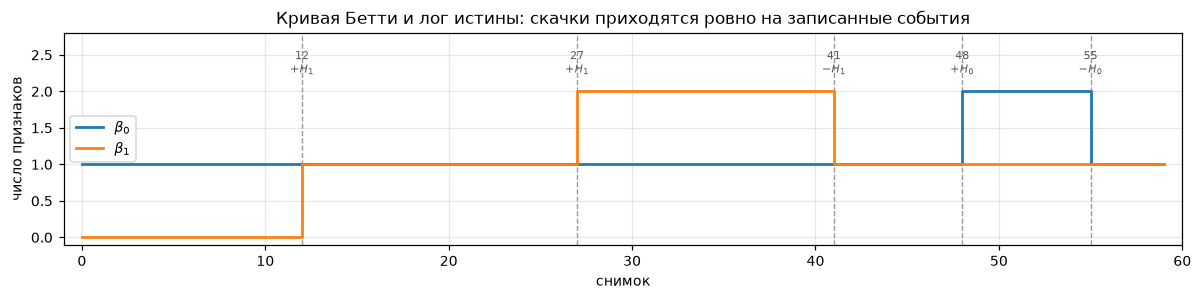

лог истины:
  снимок 12  birth  H_1  h1_a  путь замыкается в цикл
  снимок 27  birth  H_1  h1_b  хорда делит цикл на два
  снимок 41  death  H_1  h1_a  удалено ребро дуги, отрезанной хордой
  снимок 48  birth  H_0  h0_b  от висячего пути отделяется компонента
  снимок 55  death  H_0  h0_b  компоненты сливаются обратно


In [3]:
curve = LIFECYCLE.ground_truth.betti_curve
events = LIFECYCLE.ground_truth.events

fig, ax = plt.subplots(figsize=(11, 2.8))
for dim, colour in ((0, PALETTE(0)), (1, PALETTE(1))):
    ax.step(range(len(curve[dim])), curve[dim], where="post", color=colour,
            lw=1.8, label=f"$\\beta_{dim}$")
for e in events:
    ax.axvline(e.snapshot, color="0.6", ls="--", lw=0.9, zorder=0)
    ax.annotate(f"{e.snapshot}\n{'+' if e.type == 'birth' else '−'}$H_{e.dim}$",
                (e.snapshot, 2.25), ha="center", fontsize=7.5, color="0.35")
ax.set_xlim(-1, 60); ax.set_ylim(-0.1, 2.8)
ax.set_xlabel("снимок"); ax.set_ylabel("число признаков")
ax.set_title("Кривая Бетти и лог истины: скачки приходятся ровно на записанные события")
ax.legend(loc="center left"); plt.tight_layout(); plt.show()

print("лог истины:")
for e in events:
    print(f"  снимок {e.snapshot:>2}  {e.type:<6} H_{e.dim}  {e.feature_id:<5} {e.narrative}")

**Конвенция индекса**, без которой всё дальнейшее сдвинется на единицу: запись
«снимок $k$» означает, что $G_k$ **уже содержит** изменение, а $G_{k-1}$ — ещё нет. Скачок
кривой приходится на переход $k-1 \to k$.

Второй набор, `geometric_loop`, устроен принципиально иначе: там на каждом кадре лежат
**расстояния** между 24 точками на окружности, и граф строится комплексом Рипса. Радиус
окружности дышит, а дуга размыкается и смыкается по расписанию.

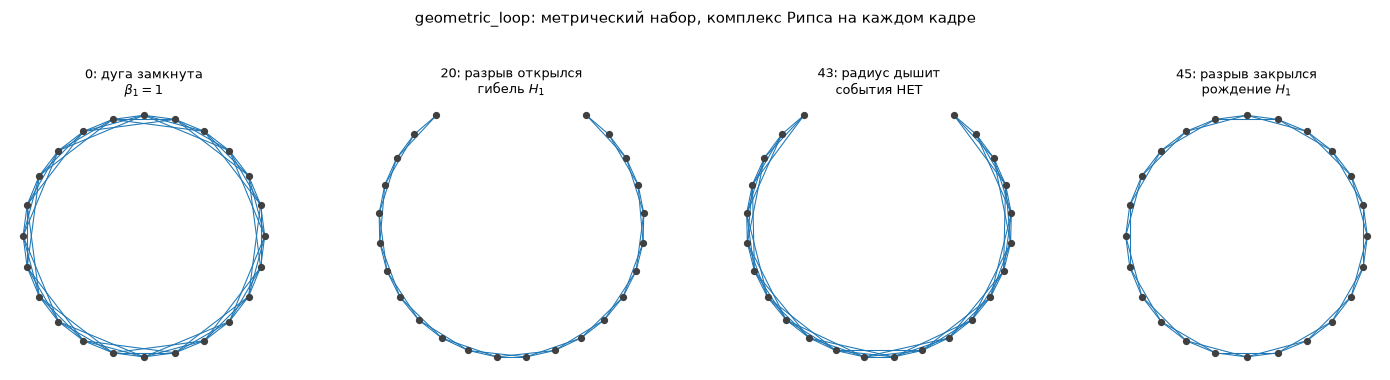

In [4]:
def loop_points(snapshot, n=24):
    """Точки кадра восстанавливаются из матрицы расстояний только ради картинки."""
    d = LOOP.snapshots[snapshot]
    # многомерное шкалирование в два измерения: классическая формула Торгерсона
    sq = d ** 2
    j = np.eye(n) - np.ones((n, n)) / n
    b = -0.5 * j @ sq @ j
    values, vectors = np.linalg.eigh(b)
    order = np.argsort(values)[::-1][:2]
    return vectors[:, order] * np.sqrt(np.maximum(values[order], 0))

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.2))
for ax, (snap, title) in zip(axes, [(0, "0: дуга замкнута\n$\\beta_1 = 1$"),
                                    (20, "20: разрыв открылся\nгибель $H_1$"),
                                    (43, "43: радиус дышит\nсобытия НЕТ"),
                                    (45, "45: разрыв закрылся\nрождение $H_1$")]):
    pts, adj = loop_points(snap), graph_at(LOOP, snap)
    for i, j2 in zip(*np.triu_indices(24, 1)):
        if adj[i, j2]:
            ax.plot(*pts[[i, j2]].T, color="tab:blue", lw=0.7, zorder=2)
    ax.scatter(*pts.T, s=14, color="0.25", zorder=3)
    ax.set_title(title, fontsize=8.5); ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("geometric_loop: метрический набор, комплекс Рипса на каждом кадре",
             y=1.06, fontsize=10)
plt.tight_layout(); plt.show()

Третья панель — **главный отрицательный контроль** метрического набора. На снимке 43 граф
меняется существенно (45 рёбер против 66), но $\beta$ не меняется, и события там нет.
Детектор, срабатывающий на любое изменение комплекса, ловится именно здесь. Таких снимков
три: 4, 43 и 56, и они проверяются поимённо.

---

## 2. Почему обычной персистентности здесь мало

В отчёте Задачи 5 фильтрация всегда **росла**: масштаб $\varepsilon$ увеличивался, симплексы
только добавлялись, и вложение $K_{\varepsilon} \subseteq K_{\varepsilon'}$ было
одностороннем. На этом стоит вся обычная персистентность.

Динамический граф так себя не ведёт. Между соседними снимками рёбра и появляются, и исчезают,
поэтому ни $G_i \subseteq G_{i+1}$, ни обратное включение не выполняются вообще говоря.

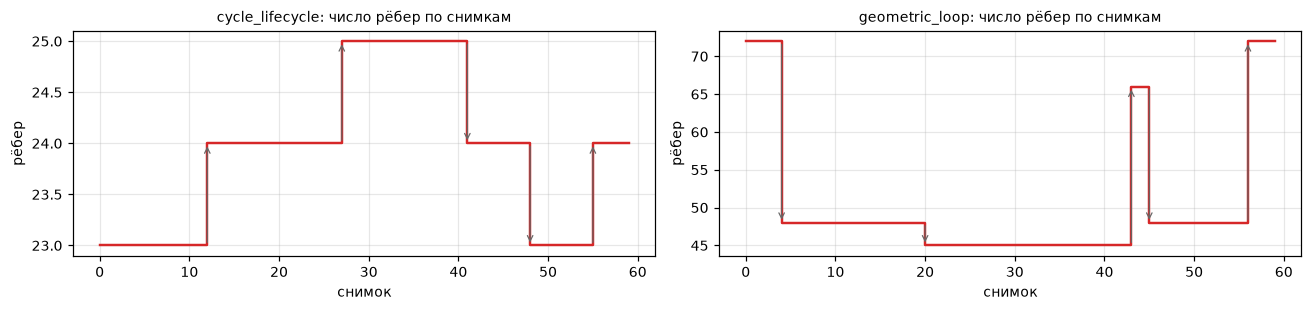

Число рёбер и растёт, и падает. Обычная фильтрация требует монотонности;
здесь её нет, и поэтому нужна другая конструкция.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 2.9), sharey=False)
for ax, (ds, name) in zip(axes, [(LIFECYCLE, "cycle_lifecycle"), (LOOP, "geometric_loop")]):
    counts = [int(graph_at(ds, t).sum() // 2) for t in range(len(ds.snapshots))]
    ax.step(range(len(counts)), counts, where="post", color=PALETTE(3), lw=1.6)
    for t in range(1, len(counts)):
        if counts[t] != counts[t - 1]:
            ax.annotate("", xy=(t, counts[t]), xytext=(t, counts[t - 1]),
                        arrowprops=dict(arrowstyle="->", color="0.4", lw=0.8))
    ax.set_title(f"{name}: число рёбер по снимкам", fontsize=9)
    ax.set_xlabel("снимок"); ax.set_ylabel("рёбер")
plt.tight_layout(); plt.show()

print("Число рёбер и растёт, и падает. Обычная фильтрация требует монотонности;")
print("здесь её нет, и поэтому нужна другая конструкция.")

Выход — **зигзаг-персистентность**: последовательность, в которой стрелки чередуют
направление. Между соседними снимками ставится их объединение, и оба снимка в него вкладываются:

$$K_0 \hookrightarrow K_0 \cup K_1 \hookleftarrow K_1 \hookrightarrow K_1 \cup K_2
\hookleftarrow \cdots \hookleftarrow K_{T-1}$$

Теперь каждая стрелка — честное вложение, и алгебра работает: такая диаграмма есть
представление колчана типа $A_N$, а по теореме Габриэля её неразложимые слагаемые — в точности
**интервальные модули**. Значит барштрих-код определён однозначно и не зависит от алгоритма,
которым его считают.

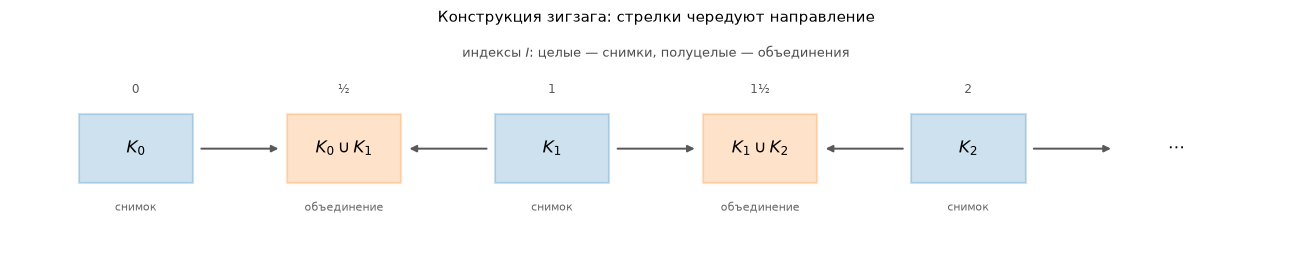

In [6]:
fig, ax = plt.subplots(figsize=(12, 2.4))
labels = ["$K_0$", "$K_0\\cup K_1$", "$K_1$", "$K_1\\cup K_2$", "$K_2$", "$\\cdots$"]
kinds = ["снимок", "объединение", "снимок", "объединение", "снимок", ""]
for k, (text, kind) in enumerate(zip(labels, kinds)):
    colour = PALETTE(0) if kind == "снимок" else (PALETTE(1) if kind else "white")
    ax.add_patch(plt.Rectangle((k * 2 - 0.55, -0.32), 1.1, 0.64, facecolor=colour,
                               alpha=0.22, edgecolor=colour if kind else "white", lw=1.4))
    ax.text(k * 2, 0, text, ha="center", va="center", fontsize=11)
    if kind:
        ax.text(k * 2, -0.55, kind, ha="center", va="center", fontsize=7.5, color="0.4")
    ax.text(k * 2, 0.52, ["0", "½", "1", "1½", "2", ""][k], ha="center",
            fontsize=8, color="0.35")
for k in range(5):
    forward = k % 2 == 0
    x0, x1 = (k * 2 + 0.6, k * 2 + 1.4) if forward else (k * 2 + 1.4, k * 2 + 0.6)
    ax.annotate("", xy=(x1, 0), xytext=(x0, 0),
                arrowprops=dict(arrowstyle="-|>", color="0.35", lw=1.3))
ax.text(5, 0.85, "индексы $I$: целые — снимки, полуцелые — объединения",
        ha="center", fontsize=8.5, color="0.3")
ax.set_xlim(-1.2, 11.2); ax.set_ylim(-0.9, 1.1); ax.axis("off")
ax.set_title("Конструкция зигзага: стрелки чередуют направление", fontsize=9.5)
plt.tight_layout(); plt.show()

### 2.1. Объединение комплексов, а не флаг-комплекс объединения графов

Развилка, которая выглядит деталью записи и ею не является. Всегда верно
$\mathrm{Fl}(G_i) \cup \mathrm{Fl}(G_j) \subseteq \mathrm{Fl}(G_i \cup G_j)$, и вообще
говоря строго: три ребра треугольника, лежащие в разных снимках, дают треугольник справа и не
дают его слева.

Принято **посимплексное объединение**, и причина не в удобстве: промежуточный объект не должен
содержать симплекс, которого нет ни в одном снимке. Иначе такой треугольник убьёт цикл на
промежуточном индексе, и в баркоде появится пара «рождение–гибель», не отвечающая никакому
состоянию данных, — причём баркод останется самосогласованным, и ни один тест его не оспорит.

Разница измерена и оказалась нулевой на всех 59 переходах обоих наборов. Это записано как
**замер**, а не как основание выбора: правило держится на принципе и переживёт первый же набор
с другой геометрией.

---

## 3. Индексы: почему концы баров бывают полуцелыми

Самое неочевидное место конструкции, и то, на котором спецификация ошибалась.

Замыкание пути на снимке 12 — это **добавление** ребра. Значит $K_{11} \subseteq K_{12}$, и
объединение $K_{11\frac12} = K_{11} \cup K_{12}$ совпадает с $K_{12}$. Цикл существует уже
там, то есть класс рождается на индексе $11\frac12$, а не на 12.

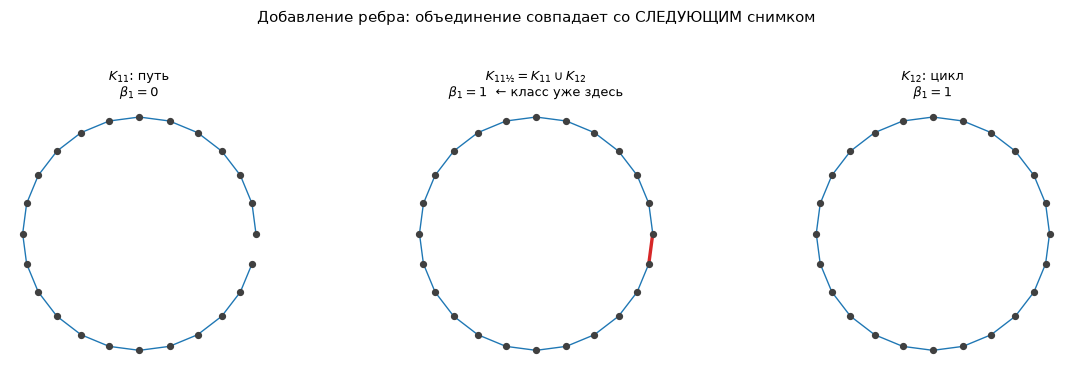

рёбер в K_11: 23;  в объединении K_11½: 24;  в K_12: 24
объединение совпало со следующим снимком, поэтому класс живёт уже на 11½


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
draw_graph(axes[0], graph_at(LIFECYCLE, 11), "$K_{11}$: путь\n$\\beta_1 = 0$")
union = np.maximum(graph_at(LIFECYCLE, 11), graph_at(LIFECYCLE, 12))
draw_graph(axes[1], union, "$K_{11½} = K_{11}\\cup K_{12}$\n$\\beta_1 = 1$  ← класс уже здесь",
           highlight=((0, 23),))
draw_graph(axes[2], graph_at(LIFECYCLE, 12), "$K_{12}$: цикл\n$\\beta_1 = 1$")
fig.suptitle("Добавление ребра: объединение совпадает со СЛЕДУЮЩИМ снимком",
             y=1.04, fontsize=9.5)
plt.tight_layout(); plt.show()

before = int(graph_at(LIFECYCLE, 11).sum() // 2)
after = int(graph_at(LIFECYCLE, 12).sum() // 2)
print(f"рёбер в K_11: {before};  в объединении K_11½: {int(union.sum() // 2)};  в K_12: {after}")
print("объединение совпало со следующим снимком, поэтому класс живёт уже на 11½")

У гибели знак противоположный. Удаление ребра $(6,7)$ на снимке 41 означает
$K_{41} \subseteq K_{40}$, поэтому объединение $K_{40\frac12}$ совпадает с **предыдущим**
снимком, и умирающий класс доживает до $40\frac12$.

А у $H_0$ всё наоборот: рождение приходит от **удаления** ребра (отделение компоненты на 48),
гибель — от **добавления** (восстановление ребра на 55), и объединение в обоих случаях
совпадает с предыдущим снимком. Отсюда целые концы.

**То есть полуцелый конец — не погрешность и не выбор, а следствие того, в какую сторону
монотонен переход.** Прежняя редакция спецификации записывала эти бары снимковыми индексами и
была неверна на полшага; исправлено замером.

---

## 4. Ответ считается дважды и разными способами

Нерушимое место всей задачи: **оракул строится раньше бэкенда**. Если сперва завести
библиотеку зигзаг-персистентности, она станет собственным эталоном, и первая же ошибка
перевода индексов закрепится как истина.

Поэтому сначала написан **независимый оракул**. Он не реализует зигзаг-алгоритм вовсе, а
считает барштрих-код по определению инварианта: для каждого интервала $[b,d]$ берётся ранг
канонического отображения из предела в копредел,

$$r(b,d) = \operatorname{rank}\bigl(\varprojlim V|_{[b,d]} \to \varinjlim V|_{[b,d]}\bigr),$$

а кратности баров восстанавливаются обращением Мёбиуса. Над $\mathbb{Z}/2$ обе конструкции —
ранги булевых матриц, и ни одной библиотеки персистентности здесь нет.

Только после этого появился Dionysus 2. Второй бэкенд проверкой не является: он повторяет тот
же класс алгоритма и при расхождении не скажет, кто прав. **Проверкой является оракул.**

сверка оракул <-> Dionysus, бар в бар, с кратностями:
  наборов       : 18
  сверено баров : 3192
  расхождений   : 0


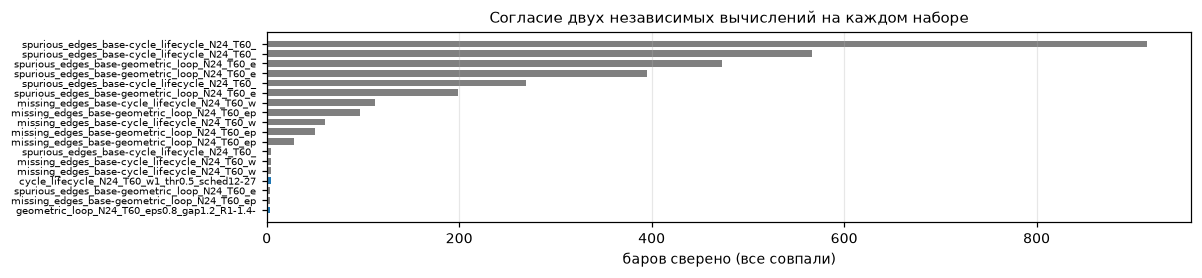

In [8]:
a = ART["agreement"]
print("сверка оракул <-> Dionysus, бар в бар, с кратностями:")
print(f"  наборов       : {a['datasets']}")
print(f"  сверено баров : {a['bars_compared']}")
print(f"  расхождений   : {a['discrepancies']}")

fig, ax = plt.subplots(figsize=(11, 2.6))
rows = sorted(ART["datasets"], key=lambda e: e["oracle_agreement"]["bars"])
names = [e["dataset_id"].split("_seed")[0][:44] for e in rows]
bars = [e["oracle_agreement"]["bars"] for e in rows]
ax.barh(range(len(rows)), bars, color=[PALETTE(0) if e["kind"] == "clean" else PALETTE(7)
                                       for e in rows], height=0.7)
ax.set_yticks(range(len(rows))); ax.set_yticklabels(names, fontsize=6.5)
ax.set_xlabel("баров сверено (все совпали)")
ax.set_title("Согласие двух независимых вычислений на каждом наборе", fontsize=9.5)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Синим — два чистых набора, серым — шестнадцать зашумлённых. Сверять согласие только там,
где в барштрих-коде четыре бара, было бы слабейшей возможной версией утверждения: ошибка
адаптера — порядок операций, интервалы присутствия симплекса, перевод полуоткрытого конца —
вероятнее проявится там, где набор даёт девятьсот баров. Это большая часть цены `make results`
и та часть, которую стоит платить.

Перед наборами адаптер валидирован на игрушках, где барштрих-код выписан руками. Одна из них,
T3, устроена как миниатюра развилки раздела 6: две раскладки с одинаковыми покрытиями, и
Dionysus выбирает верную.

---

## 5. Барштрих-код

Каждый бар — интервал на множестве индексов $I$: класс родился на левом конце и дожил до
правого. Отчёт печатает индексы так, как их пишут документы: `12` для снимка, `11½` для
объединения между 11 и 12.

cycle_lifecycle:
  H_0: [0, 59], [48, 54]
  H_1: [11½, 40½], [26½, 59]
geometric_loop:
  H_0: [0, 59]
  H_1: [0, 19½], [44½, 59]


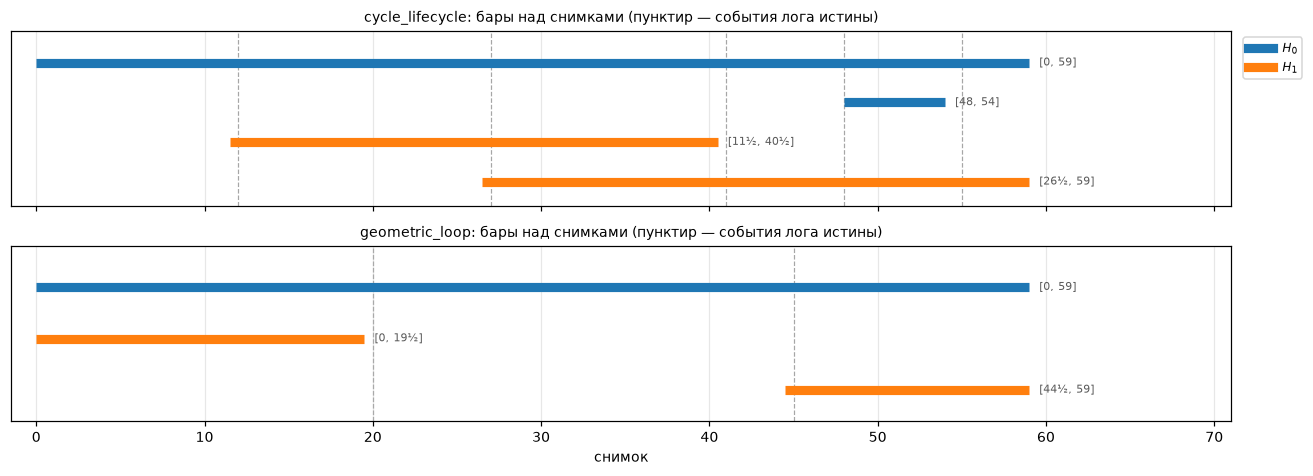

In [9]:
for name, e in CLEAN.items():
    print(f"{name}:")
    for dim, bars in sorted(e["barcode"].items()):
        print(f"  H_{dim}: " + ", ".join(f"[{label(b)}, {label(d)}]" for b, d in bars))

fig, axes = plt.subplots(2, 1, figsize=(12, 4.4), sharex=True)
for ax, (name, e) in zip(axes, CLEAN.items()):
    y = 0
    for dim, bars in sorted(e["barcode"].items()):
        for b, d in bars:
            ax.plot([b / 2, d / 2], [y, y], lw=6, solid_capstyle="butt",
                    color=PALETTE(int(dim)))
            ax.annotate(f"[{label(b)}, {label(d)}]", (d / 2 + 0.6, y),
                        va="center", fontsize=7, color="0.35")
            y -= 1
    for ev in e["events"] or []:
        if not ev["censored"]:
            ax.axvline(ev["snapshot"], color="0.65", ls="--", lw=0.8, zorder=0)
    ax.set_ylim(y + 0.4, 0.8); ax.set_yticks([]); ax.set_xlim(-1.5, 71)
    ax.set_title(f"{name}: бары над снимками (пунктир — события лога истины)", fontsize=9)
axes[-1].set_xlabel("снимок")
handles = [plt.Line2D([], [], color=PALETTE(d), lw=6, label=f"$H_{d}$") for d in (0, 1)]
axes[0].legend(handles=handles, loc="upper left", bbox_to_anchor=(1.005, 1.0), fontsize=8)
plt.tight_layout(); plt.show()

Четыре бара `cycle_lifecycle` и пять его событий сходятся так: три рождения (12, 27, 48)
видимы; рождение бесконечного бара $H_0$ **левоцензурировано** — класс уже был, когда
наблюдение началось; гибели баров $[26½, 59]$ и $[0,59]$ **правоцензурированы** — окно
кончилось раньше.

У `geometric_loop` второй бар $H_1$ **не может** быть продолжением первого: между снимками 20
и 44 класса нет вовсе, а интервалы связны. Это и есть содержательная разница между «петля
вернулась» на языке графов и двумя разными классами на языке гомологий.

---

## 6. Спаривание: почему гибель на 41 принадлежит рождению на 12

Самое тонкое утверждение всей задачи, и то, где интуиция подводит.

После добавления хорды в $H_1$ два класса, и на снимке 41 один из них умирает. Какой?
Напрашивается: «хорда породила второй цикл, ломаем ребро одного из них — умирает молодой».
**Это неверно.** Умирает класс, рождённый при замыкании пути, то есть пара 12↔41.

И это не конвенция, которую можно назначить: разложение зигзаг-модуля на интервалы однозначно
(Габриэль, Крулль–Шмидт), а ответ зависит от того, какое именно ребро удалено, — то есть
определён геометрией. Проверяется он вычислением: в вершине класс, принесённый слева, и класс,
доживающий справа, натягивают **разные прямые** двумерного пространства, поэтому оно
распадается в прямую сумму и бар слева дальше вершины не идёт.

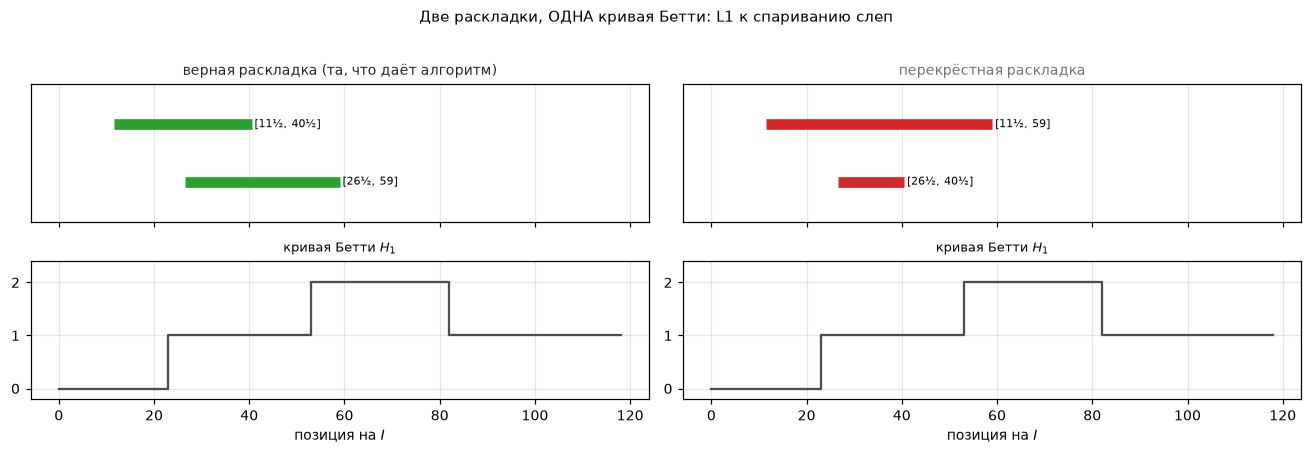

кривые Бетти совпадают: True
барштрих-коды различны : True

Алгоритм выбрал: [11½, 40½], [26½, 59]


In [10]:
cl = CLEAN["cycle_lifecycle"]
bars = cl["barcode"]["1"]
births = sorted(b for b, _ in bars); deaths = sorted(d for _, d in bars)
correct = [(births[0], deaths[0]), (births[1], deaths[1])]
crossed = [(births[0], deaths[1]), (births[1], deaths[0])]

def betti_from(pairing, n=119):
    return [sum(1 for b, d in pairing if b <= p <= d) for p in range(n)]

fig, axes = plt.subplots(2, 2, figsize=(12, 4.0), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1]})
for col, (pairing, title, ok) in enumerate(
        [(correct, "верная раскладка (та, что даёт алгоритм)", True),
         (crossed, "перекрёстная раскладка", False)]):
    ax = axes[0, col]
    for k, (b, d) in enumerate(pairing):
        ax.plot([b / 2, d / 2], [-k, -k], lw=7, solid_capstyle="butt",
                color=PALETTE(2) if ok else PALETTE(3))
        ax.annotate(f"[{label(b)}, {label(d)}]", (d / 2 + 0.6, -k), va="center", fontsize=7.5)
    ax.set_ylim(-1.7, 0.7); ax.set_yticks([])
    ax.set_title(title, fontsize=9, color="0.15" if ok else "0.45")
    axes[1, col].step(range(119), [v / 1 for v in betti_from(pairing)], where="post",
                      color="0.3", lw=1.5)
    axes[1, col].set_ylim(-0.2, 2.4); axes[1, col].set_xlabel("позиция на $I$")
    axes[1, col].set_title("кривая Бетти $H_1$", fontsize=8.5)
fig.suptitle("Две раскладки, ОДНА кривая Бетти: L1 к спариванию слеп", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

print("кривые Бетти совпадают:", betti_from(correct) == betti_from(crossed))
print("барштрих-коды различны :", sorted(correct) != sorted(crossed))
print()
print("Алгоритм выбрал:", ", ".join(f"[{label(b)}, {label(d)}]" for b, d in sorted(bars)))

Обе раскладки дают **одну и ту же** кривую Бетти и одни и те же ранги стрелок. Различает
только полный инвариант — тот самый обобщённый ранг с обращением Мёбиуса из раздела 4.

Это третий по счёту случай одной и той же слепоты в проекте. В Задаче 5 кривая Бетти не
различала спаривание; здесь его не различают покрытия вершин и стрелок; а в разделе 8 окажется,
что его не различает и лог событий.

---

## 7. Из барштрих-кода в лог событий

Бар живёт на $I$, а лог истины говорит про снимки. Перевод — два асимметричных правила:

- **рождение** попадает на первый снимковый индекс **не раньше** рождения бара;
- **гибель** — на первый снимковый индекс **строго позже** его гибели.

Привычный сдвиг $d \mapsto d+1$ есть вторая половина правила при целом конце, а не отдельное
правило. Он вводится ровно в одном месте кода и имеет отдельный тест: расхождение на единицу
здесь выглядит в отчёте систематической ошибкой локализации алгоритма и неотличимо от неё.

Прежняя редакция спецификации отправляла полуцелые концы в особую категорию «событие в
переходе». Замер показал, что так лог не восстанавливается: у `cycle_lifecycle` **оба**
$H_1$-бара имеют полуцелые концы, и правило давало бы «в переходе» там, где истина записывает
обычные рождение на 12 и гибель на 41.

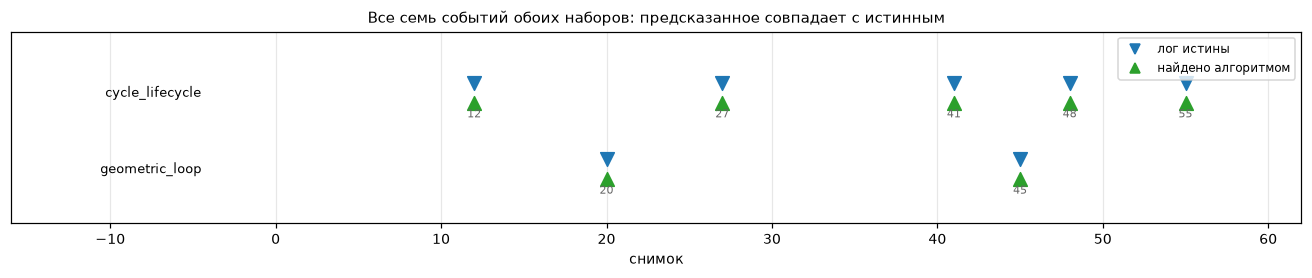

cycle_lifecycle: 5 событий — 12:bH1, 27:bH1, 41:dH1, 48:bH0, 55:dH0
geometric_loop: 2 событий — 20:dH1, 45:bH1


In [11]:
fig, ax = plt.subplots(figsize=(12, 2.6))
for name, e in CLEAN.items():
    row = 0 if name == "cycle_lifecycle" else -1
    truth = LIFECYCLE if row == 0 else LOOP
    for ev in truth.ground_truth.events:
        ax.scatter(ev.snapshot, row + 0.13, marker="v", s=80, color=PALETTE(0), zorder=3)
    for ev in e["events"] or []:
        if ev["censored"]:
            continue
        ax.scatter(ev["snapshot"], row - 0.13, marker="^", s=80, color=PALETTE(2), zorder=3)
        ax.annotate(f"{ev['snapshot']}", (ev["snapshot"], row - 0.32), ha="center",
                    fontsize=7, color="0.4")
    ax.text(-4.5, row, name, ha="right", va="center", fontsize=8.5)
ax.set_xlim(-16, 62); ax.set_ylim(-1.7, 0.8); ax.set_yticks([])
ax.set_xlabel("снимок")
ax.legend(handles=[plt.Line2D([], [], marker="v", ls="", color=PALETTE(0), label="лог истины"),
                   plt.Line2D([], [], marker="^", ls="", color=PALETTE(2), label="найдено алгоритмом")],
          loc="upper right", fontsize=8)
ax.set_title("Все семь событий обоих наборов: предсказанное совпадает с истинным", fontsize=9.5)
plt.tight_layout(); plt.show()

for name, e in CLEAN.items():
    got = sorted((v["snapshot"], v["dim"], v["type"]) for v in (e["events"] or [])
                 if not v["censored"])
    print(f"{name}: {len(got)} событий — " +
          ", ".join(f"{s}:{t[0]}H{d}" for s, d, t in got))

---

## 8. Результат 2: метрики — и что они **не** проверяют

Сопоставление идёт только внутри пары `(тип, размерность)`, с допуском $\tau$ по индексу
снимка. Умолчание $\tau = 0$: сматчиться может только точное совпадение.

In [12]:
print(f"{'набор':<18}{'recall':<9}{'precision':<12}{'|dt| max':<10}{'по размерностям'}")
for name, e in CLEAN.items():
    m = e["metrics"]
    per = "  ".join(f"H_{d}: {v['n_matched']}/{v['n_truth']}"
                    for d, v in sorted(m["by_dimension"].items()) if v["n_truth"])
    print(f"{name:<18}{m['recall']:<9.3f}{m['precision']:<12.3f}"
          f"{m['max_localisation_error']:<10}{per}")

набор             recall   precision   |dt| max  по размерностям
cycle_lifecycle   1.000    1.000       0         H_0: 2/2  H_1: 3/3
geometric_loop    1.000    1.000       0         H_1: 2/2


**Единицы здесь — ожидаемый исход, а не достижение.** Наборы построены так, что ответ
известен заранее, а алгоритм точен; было бы странно получить что-то другое. Ценность метрики в
том, что под шумом она единицей быть перестаёт (раздел 11), и говорить об этом обязан отчёт, а
не читатель.

Метрики считаются **раздельно по размерностям**, и это не формальность: пять событий
`cycle_lifecycle` распределены как три в $H_1$ и два в $H_0$, и сводный recall скрыл бы
алгоритм, безупречный в одной размерности и слепой в другой.

**Ошибка локализации при $\tau = 0$ тождественно нулевая** — сматчиться может только точное
попадание. Она публикуется, потому что этого требует спецификация, но информативной величиной
не является. Замерено: на восьми зашумлённых наборах поднятие допуска до единицы возвращает
одно событие в одном из них, то есть под шумом отказ — пропуск и наводнение ложными, а не
смещение.

**Цензурированные события помечаются и в метрики не входят.** Цензурированное рождение не
заявляет, что класс родился; оно говорит, что класс уже был, когда окно открылось. Считать его
ложным срабатыванием значило бы штрафовать алгоритм за конечность наблюдения.

### 8.1. Граница Результата 2

Событие не помнит, из какого бара оно выведено. Поэтому верная раскладка $H_1$ и перекрёстная
из раздела 6 дают **побитово одинаковый лог событий**, и recall с precision пару 12↔41 **не
проверяют**. Её проверяет сверка барштрих-кодов из раздела 4.

In [13]:
def events_of(pairing, n=119):
    out = []
    for b, d in pairing:
        if b > 0:
            out.append((next(p for p in range(b, n) if p % 2 == 0) // 2, "birth"))
        if d < n - 1:
            out.append((next(p for p in range(d + 1, n) if p % 2 == 0) // 2, "death"))
    return sorted(out)

print("верная раскладка     ->", events_of(correct))
print("перекрёстная         ->", events_of(crossed))
print()
print("логи совпадают:", events_of(correct) == events_of(crossed))
print()
print("Значит recall и precision пару 12<->41 НЕ подтверждают.")
print("Её подтверждает сверка барштрих-кодов: 3192 бара, 0 расхождений (раздел 4).")

верная раскладка     -> [(12, 'birth'), (27, 'birth'), (41, 'death')]
перекрёстная         -> [(12, 'birth'), (27, 'birth'), (41, 'death')]

логи совпадают: True

Значит recall и precision пару 12<->41 НЕ подтверждают.
Её подтверждает сверка барштрих-кодов: 3192 бара, 0 расхождений (раздел 4).


Это та же слепота, что у кривой Бетти в Задаче 5 и у покрытий в разделе 6, на уровень
дальше: **кривая → покрытия → лог событий**. Каждый следующий уровень отчётности теряет
спаривание заново, и об этом надо говорить в отчёте, а не подразумевать.

---

## 9. Четыре величины, которые считаются и протоколируются

Ни одна из них не отбрасывается молча, потому что каждая — характеристика конструкции, а не
шум реализации.

In [14]:
print(f"{'набор':<18}{'невидимых':<11}{'цензур.':<9}{'из полуцелого':<15}"
      f"{'эфемерных (пролог + вне)'}")
for name, e in CLEAN.items():
    k = e["counters"]
    print(f"{name:<18}{k['invisible_bars']:<11}{k['censored_ends']:<9}"
          f"{k['events_from_half_integer_ends']:<15}"
          f"{k['ephemeral_bars']} = {k['ephemeral_in_prologue']} + "
          f"{k['ephemeral_outside_prologue']}")

набор             невидимых  цензур.  из полуцелого  эфемерных (пролог + вне)
cycle_lifecycle   0          3        3              23 = 23 + 0
geometric_loop    0          4        2              165 = 71 + 94


**Невидимый бар** не содержит в носителе ни одного снимкового индекса: класс не существует
ни в одном состоянии данных, он живёт только на объединении. Такой бар — ложное срабатывание
по построению. На чистых наборах их ноль, и это замер, а не умолчание.

**Цензурированный конец** касается границы последовательности: класс уже был, когда наблюдение
началось, или ещё был, когда оно кончилось.

**Событие из полуцелого конца** — диагностика конструкции объединения. У `cycle_lifecycle` три
события из пяти выведены из полуцелого конца, у `geometric_loop` — оба.

**Эфемерный бар** рождается и умирает внутри одного перехода. Грубому пути и оракулу они
недоступны по построению: ни один индекс диаграммы их не застаёт. Видны они только на тонком
пути, где бэкенду даётся по одному времени на **операцию**, а не на индекс.

И тут важна оговорка. Число публикуется **разложенным** на пролог и остальное, потому что
прологовая часть измеряет не данные, а порядок сборки первого комплекса: построение 24-цикла из
пустого комплекса рождает 24 компоненты и убивает 23 из них. Этот порядок зафиксирован
лексикографически и произволен по существу.

---

## 10. Нулевая модель: измерение, а не проверка на ноль

У нулевой модели расписания нет и лог событий пуст, поэтому **любое** событие есть ложное
срабатывание. Правильный ответ — не «ноль срабатываний», а частота с числом испытаний и
доверительным интервалом.

Это урок Задачи 5, и он стоил там отдельного разбора: три сида, давшие ноль промахов,
ограничивают истинную частоту **63 процентами**, а не нулём. Ноль без знаменателя — не
результат.

ER при плотности cycle_lifecycle, 3 сида x 20 реализаций
  на снимок      0.9833  (3540/3600, 95% Уилсон [0.9786, 0.9870])
  на реализацию  1.0000  (60/60, 95% Уилсон [0.9398, 1.0000])
  событий: 46323 (H_0: 25710, H_1: 20613)
  на снимок: 12.9


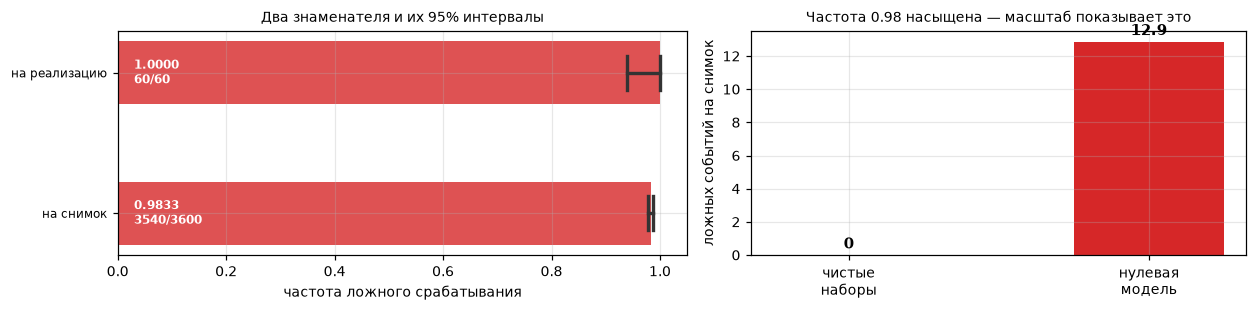

In [15]:
n = ART["null_model"]
print(f"ER при плотности cycle_lifecycle, {len(n['seeds'])} сида x "
      f"{n['realizations']} реализаций")
for key, name in (("per_snapshot", "на снимок"), ("per_realisation", "на реализацию")):
    r = n[key]; lo, hi = r["interval"]
    print(f"  {name:<15}{r['rate']:.4f}  ({r['hits']}/{r['trials']}, "
          f"95% Уилсон [{lo:.4f}, {hi:.4f}])")
print(f"  событий: {n['events']} "
      f"({', '.join(f'H_{d}: {c}' for d, c in sorted(n['events_by_dimension'].items()))})")
print(f"  на снимок: {n['events_per_snapshot']:.1f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 2.9),
                                  gridspec_kw={"width_ratios": [1.15, 1]})
for k, (key, name) in enumerate((("per_snapshot", "на снимок\n(испытания\nкоррелированы)"),
                                 ("per_realisation", "на реализацию\n(независимы,\nно их 60)"))):
    r = n[key]; lo, hi = r["interval"]
    left.barh(k, r["rate"], height=0.45, color=PALETTE(3), alpha=0.8)
    left.plot([lo, hi], [k, k], color="0.2", lw=2.2)
    left.plot([lo, lo], [k - .12, k + .12], color="0.2", lw=2.2)
    left.plot([hi, hi], [k - .12, k + .12], color="0.2", lw=2.2)
    left.annotate(f"{r['rate']:.4f}\n{r['hits']}/{r['trials']}", (0.03, k),
                  va="center", fontsize=8, color="white", weight="bold")
left.set_yticks([0, 1]); left.set_yticklabels(["на снимок", "на реализацию"], fontsize=8)
left.set_xlim(0, 1.05); left.set_xlabel("частота ложного срабатывания")
left.set_title("Два знаменателя и их 95% интервалы", fontsize=9)

right.bar(["чистые\nнаборы", "нулевая\nмодель"], [0, n["events_per_snapshot"]],
          color=[PALETTE(2), PALETTE(3)], width=0.5)
right.annotate(f"{n['events_per_snapshot']:.1f}", (1, n["events_per_snapshot"] + 0.4),
               ha="center", fontsize=10, weight="bold")
right.annotate("0", (0, 0.4), ha="center", fontsize=10, weight="bold")
right.set_ylabel("ложных событий на снимок")
right.set_title("Частота 0.98 насыщена — масштаб показывает это", fontsize=9)
plt.tight_layout(); plt.show()

**Каждый снимок нулевой модели есть топологическое событие.** Это не дефект алгоритма:
случайный граф при этой плотности честно имеет $\beta_0 = 4\ldots5$ и $\beta_1 = 2\ldots5$
на каждом снимке, а рёбра перерисовываются независимо, поэтому классы рождаются и умирают
непрерывно.

Публикуются **оба знаменателя**, потому что ни один в отдельности не честен. На снимок — это
то, что требует спецификация, но испытания там не независимы: соседние комплексы делят рёбра,
и интервал уже истинного. На реализацию — испытания независимы, но их шестьдесят, и интервал
широк. Третьей строкой идёт число событий на снимок, потому что частота 0.98 насыщена и о
масштабе не говорит.

Порог `null_models.max_false_positive_rate` сюда **не применяется**, хотя называется ровно
этим. Он откалиброван для критерия значимости на облаках Задачи 5 — доля реализаций, где
критерий выдумал признак, 1.5% при границе 4.3%. Зигзаг меряет долю снимков со срабатыванием.
Сравнить их значило бы объявить провал, измеряя разные величины.

---

## 11. Деградация под шумом

In [16]:
rows = sorted(NOISY, key=lambda e: (e["noise"]["kind"], e["base"], e["noise"]["level"]))
print(f"{'механизм':<10}{'база':<17}{'ур.':<6}{'баров':<7}{'recall':<8}{'precision':<11}"
      f"{'невид.':<8}{'цензур.':<9}{'полуцел.':<10}{'эфем. вне пролога'}")
for e in rows:
    m, k = e["metrics"], e["counters"]
    nbars = sum(len(v) for v in e["barcode"].values())
    print(f"{e['noise']['kind'][:9]:<10}{e['base'].split('_N')[0]:<17}"
          f"{e['noise']['level']:<6}{nbars:<7}{m['recall']:<8.3f}{m['precision']:<11.4f}"
          f"{k['invisible_bars']:<8}{k['censored_ends']:<9}"
          f"{k['events_from_half_integer_ends']:<10}{k['ephemeral_outside_prologue']}")

механизм  база             ур.   баров  recall  precision  невид.  цензур.  полуцел.  эфем. вне пролога
missing_e cycle_lifecycle  0.0   4      1.000   1.0000     0       3        3         0
missing_e cycle_lifecycle  0.02  4      1.000   1.0000     0       3        3         0
missing_e cycle_lifecycle  0.05  61     0.800   0.0506     19      5        35        0
missing_e cycle_lifecycle  0.1   113    0.600   0.0201     36      5        20        0
missing_e geometric_loop   0.0   3      1.000   1.0000     0       4        2         94
missing_e geometric_loop   0.02  28     1.000   0.0385     0       4        6         200
missing_e geometric_loop   0.05  50     1.000   0.0208     0       4        10        336
missing_e geometric_loop   0.1   97     1.000   0.0109     3       4        69        531
spurious_ cycle_lifecycle  0.0   4      1.000   1.0000     0       3        3         0
spurious_ cycle_lifecycle  0.02  269    0.800   0.0078     6       13       511       54
spurious

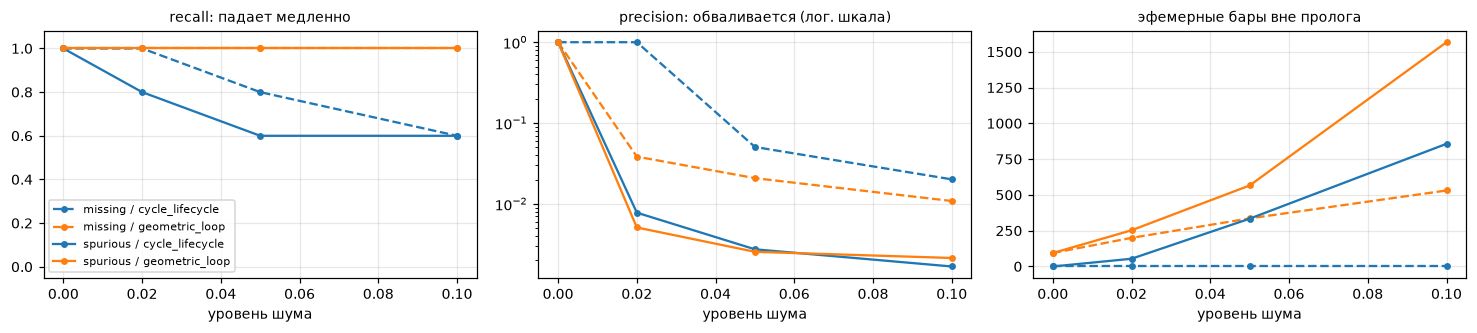

In [17]:
series = {}
for e in NOISY:
    key = (e["noise"]["kind"].split("_")[0], e["base"].split("_N")[0])
    series.setdefault(key, []).append((e["noise"]["level"], e["metrics"], e["counters"]))
for points in series.values():
    points.sort()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.1))
styles = {"spurious": "-", "missing": "--"}
colours = {"cycle_lifecycle": PALETTE(0), "geometric_loop": PALETTE(1)}
for (kind, base), points in sorted(series.items()):
    lv = [p[0] for p in points]
    axes[0].plot(lv, [p[1]["recall"] for p in points], styles[kind],
                 color=colours[base], marker="o", ms=3.5, label=f"{kind} / {base}")
    axes[1].semilogy(lv, [p[1]["precision"] for p in points], styles[kind],
                     color=colours[base], marker="o", ms=3.5)
    axes[2].plot(lv, [p[2]["ephemeral_outside_prologue"] for p in points], styles[kind],
                 color=colours[base], marker="o", ms=3.5)
axes[0].set_ylim(-0.05, 1.08); axes[0].set_title("recall: падает медленно", fontsize=9)
axes[1].set_title("precision: обваливается (лог. шкала)", fontsize=9)
axes[2].set_title("эфемерные бары вне пролога", fontsize=9)
for ax in axes:
    ax.set_xlabel("уровень шума")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

Три наблюдения, каждое из которых видно на рисунке.

**recall падает медленно, precision обваливается.** У `cycle_lifecycle` точность доходит до
0.17%: алгоритм не столько теряет события, сколько наводняет лог ложными. Отказ под шумом —
не смещение во времени, а потоп.

**`geometric_loop` держит recall на единице при всех уровнях.** Оба его события находятся
всегда; портится только точность. Это свойство наборов, а не шум измерения, и сводка по
шестнадцати строкам его бы скрыла.

**`spurious_edges` вреднее `missing_edges` на порядок.** Добавленное ребро создаёт циклы;
удалённое чаще всего лишь разрывает существующий.

Уровень 0.0 воспроизводит чистый набор точно — бесплатная проверка, ловящая разом неверно
подключённую базу, сдвиг потока случайности между уровнями и безусловный `clip`.

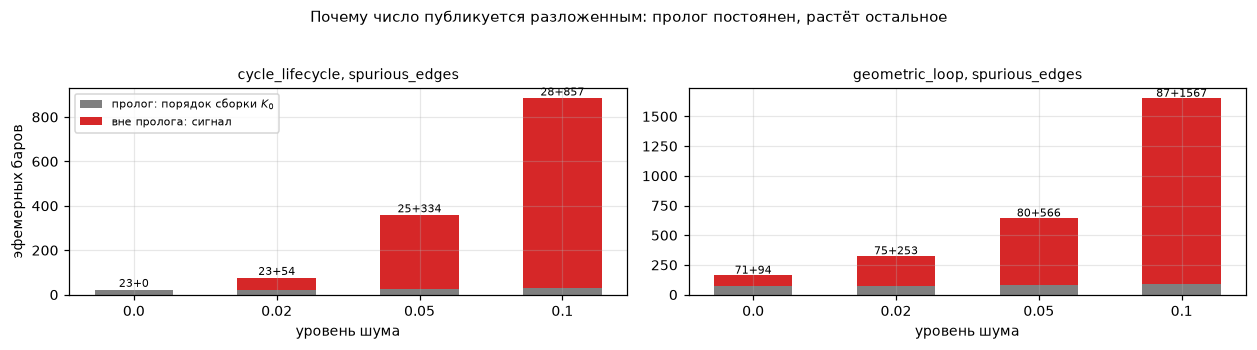

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.0), sharey=False)
for ax, base in zip(axes, ["cycle_lifecycle", "geometric_loop"]):
    points = sorted(series[("spurious", base)])
    lv = [p[0] for p in points]
    inside = [p[2]["ephemeral_in_prologue"] for p in points]
    outside = [p[2]["ephemeral_outside_prologue"] for p in points]
    x = np.arange(len(lv))
    ax.bar(x, inside, width=0.55, color=PALETTE(7), label="пролог: порядок сборки $K_0$")
    ax.bar(x, outside, width=0.55, bottom=inside, color=PALETTE(3),
           label="вне пролога: сигнал")
    for k, (a, b) in enumerate(zip(inside, outside)):
        ax.annotate(f"{a}+{b}", (k, a + b + 12), ha="center", fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels(lv); ax.set_xlabel("уровень шума")
    ax.set_title(f"{base}, spurious_edges", fontsize=9)
axes[0].set_ylabel("эфемерных баров"); axes[0].legend(fontsize=7.5, loc="upper left")
fig.suptitle("Почему число публикуется разложенным: пролог постоянен, растёт остальное",
             y=1.04, fontsize=9.5)
plt.tight_layout(); plt.show()

Прологовая часть дрейфует на единицы (23 → 28 и 71 → 87), а часть вне его растёт на
порядки (0 → 857 и 94 → 1567). При нулевом шуме сумма **целиком** состоит из пролога, поэтому
без разложения нулевая точка отсчёта была бы ложной, а «рост числа эфемерных баров под шумом»
измерялся бы от неверного начала.

---

## 12. Границы применимости

Их надо назвать, потому что каждая — место, где число из этого отчёта перестанет что-либо
означать.

**Барштрих-код зависит от конвенции объединения.** Коды, полученные при разных конвенциях,
несравнимы. Поэтому конвенция лежит в самом артефакте, рядом с барами, а не выводится из
коммита, в котором файл появился.

In [19]:
c = ART["convention"]
print(f"правило объединения : {c['union_rule']}")
print(f"поле коэффициентов  : Z/{c['coeff_field']}")
print(f"размерность         : до H_{c['max_homology_dim']}")
print(f"бэкенд              : {c['backend']}")
print(f"допуск сопоставления: tau = {c['event_matching']['tolerance']}")
print()
print(c["index_convention"])

правило объединения : complex_union
поле коэффициентов  : Z/2
размерность         : до H_1
бэкенд              : dionysus
допуск сопоставления: tau = 0

barcodes live on I = {0, 1/2, 1, ..., T-1}: integer positions are snapshots, half-integer ones the unions between them. An event is placed on the first snapshot index at or after a birth and strictly after a death (docs/zigzag.md 4.2).


**Обрезка комплекса.** Комплексы строятся до размерности $k_{\max}+1$, и бары размерности
$k_{\max}$ достоверны. Размерность выше не вычисляется, и её отсутствие в выводе **не есть
утверждение** о её отсутствии в данных.

Бэкенд такие бары возвращает — на метрическом наборе их 69 в $H_2$, — и адаптер их отсекает.
Что это артефакты, а не находка, известно не по умолчанию: генератор строил свои комплексы на
размерность выше, с нужным граничным оператором, и записал $\beta_2 = 0$ на каждом снимке.
69 баров противоречат числу, которое **было** посчитано правильно.

**Значимость бара в зигзаге не определена.** Параметры критерия из Задачи 5 сюда не
наследуются: они откалиброваны на облаках точек, и, кроме того, критерий не инвариантен
относительно перепараметризации фильтрации. Замена в этой ветке не вводится — и раздел 10
показывает, что вопрос не академический: без критерия точность на шуме падает до 0.17%, а на
нулевой модели срабатывает 98% снимков.

**Ошибка локализации при $\tau = 0$** информации не несёт (раздел 8).

---

## 13. Что сделано и чем это проверено

Кратко, по слоям, — чтобы читателю было видно, где что искать в коде.

In [20]:
summary = [
    ("core", "контракты, конфиг, чтение наборов", "правило ребра — одна реализация"),
    ("reference", "гомологии над Z/2, зигзаг-оракул", "игрушки с ответом, выписанным руками"),
    ("zigzag", "комплексы, поток операций, бэкенд, события", "реплей потока, согласие с оракулом"),
    ("results", "сборка артефакта", "пересборка даёт тот же хеш"),
]
print(f"{'слой':<12}{'что делает':<44}{'чем проверен'}")
for layer, does, checked in summary:
    print(f"{layer:<12}{does:<44}{checked}")
print()
print(f"артефакт: {len(ART['datasets'])} наборов, "
      f"{ART['agreement']['bars_compared']} баров сверено, "
      f"{ART['agreement']['discrepancies']} расхождений")
print(f"хеш содержимого: {ART['content_sha256']}")

слой        что делает                                  чем проверен
core        контракты, конфиг, чтение наборов           правило ребра — одна реализация
reference   гомологии над Z/2, зигзаг-оракул            игрушки с ответом, выписанным руками
zigzag      комплексы, поток операций, бэкенд, события  реплей потока, согласие с оракулом
results     сборка артефакта                            пересборка даёт тот же хеш

артефакт: 18 наборов, 3192 баров сверено, 0 расхождений
хеш содержимого: 6be89481b849170e5db7e22ea0d17e9a2143f7c8950cf27cde006a6c1a25d145


Зависимости между слоями односторонни: слой, производящий истину, не знает о слое, который
её потребляет. `zigzag` не импортирует генераторы — он читает наборы через `core`; `reference`
не импортирует ни того, ни другого. Единственное исключение названо и проверяется тестом:
`tdadyn.results` — композиционный корень, которому нужны оба слоя, и потому он стоит над ними,
а не внутри одного.

Три цели прогона: `make fast` (без зигзаг-бэкендов, 16 с), `make slow` (топология Задачи 5,
около десяти минут), `make zigzag` (оракул и бэкенд, 5:43 — из них 4:46 единственная
пересборка артефакта в тесте на воспроизводимость хеша).

## 14. Что дальше

| | |
|---|---|
| **Vineyards** | отслеживают перемещение точек диаграммы при **непрерывном** изменении фильтрации: точки ползут, пересекаются, меняются местами. Зигзаг здесь дискретен по построению — между целым и полуцелым индексом не происходит ничего, что можно отследить непрерывно. Это другой объект, а не отложенная работа, и нужен он там, где фильтрация непрерывна: Задача 3 и бифильтрация Результата 3 |
| **Значимость бара** | ставится заново и решается не подбором порога под precision |
| **Коннектомы** | числа невидимых и эфемерных баров из раздела 9 — то, что надо знать до переноса: оба суть ложные срабатывания по построению конструкции объединения |
| **Открытый пункт** | медленный прогон вырос за Задачу 2 с 10:10 до 10:48 при ориентире 15 минут; запаса четыре минуты, и лечить придётся делением целей, а не ослаблением проверок |